# Mini Project: COVID-19 Detection from Chest X-rays using CNN

## Project Objective
A healthcare startup aims to accelerate and improve COVID-19 diagnosis using deep learning technologies. Traditional testing and manual radiological reviews are time-consuming and difficult to scale during pandemic surges.

This notebook builds an end-to-end **Convolutional Neural Network (CNN)** pipeline to classify chest X-ray images into three categories:
- **COVID-19** – Confirmed COVID-19 infection
- **Viral Pneumonia** – Non-COVID viral lung infection
- **Normal** – No visible lung abnormality

### Pipeline Covered
1. **Data Loading & Exploration** (Kaggle API import, loading, resizing, sample visualization)
2. **Data Preprocessing** (Normalization, label encoding, stratified Train/Val/Test split)
3. **Exploratory Data Analysis (EDA)** (Class distribution, sample grids, image & intensity patterns)
4. **CNN Model Building** (Basic CNN, Deep CNN, Transfer Learning with VGG16 & ResNet50, Transfer Learning + Data Augmentation)
5. **Model Evaluation** (Test Accuracy, Confusion Matrix, Classification Report, Multi-class ROC-AUC, Overfitting plots, Trainable Parameters)
6. **Handling Class Imbalance** (Visual analysis, Class Weights, Minority-class Oversampling via Data Augmentation)
7. **Model Tuning** (EarlyStopping, ReduceLROnPlateau, Keras Tuner hyperparameter optimization)
8. **Model Comparison Table & Saving Best Model**
9. **Streamlit Web Application** (`app.py` for real-time chest X-ray prediction)

---
## 1. Data Loading and Exploration

### 1.1 Install Required Packages (for Google Colab / Local Environment)

In [2]:
# Install required packages if not already installed
!pip install -q kaggle keras-tuner streamlit scikit-learn seaborn opencv-python-headless

### 1.2 Import Necessary Libraries

In [3]:
import os
import json
import random
import shutil
import subprocess
import warnings
warnings.filterwarnings("ignore")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50
import keras_tuner as kt

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.3 Import COVID-19 Dataset from Kaggle into Google Colab using Kaggle API

**Steps to set up Kaggle API in Google Colab:**
1. Go to [Kaggle Account Settings](https://www.kaggle.com/settings) and click **Create New Token** to download `kaggle.json`.
2. Run the cell below and upload your `kaggle.json` file when prompted.
3. *(If running locally, place `kaggle.json` in `~/.kaggle/` or download and unzip the dataset manually into `./covid19-image-dataset/`.)*

In [4]:
# Download dataset from Kaggle using Kaggle API
DATASET_SLUG = "pranavraikokte/covid19-image-dataset"
DATA_DIR = "covid19-image-dataset"

# Set your Kaggle API Token
os.environ["KAGGLE_API_TOKEN"] = "KGAT_1c6a7fdcf36e5663d73f9e97405f83b4"

if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", DATASET_SLUG, "-p", DATA_DIR, "--unzip"],
        check=True
    )
else:
    print(f"Dataset directory '{DATA_DIR}' already exists.")

# Inspect extracted folder structure
for root, dirs, files_list in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/ ({len(files_list)} files)")

covid19-image-dataset/ (0 files)
  Covid19-dataset/ (0 files)
    train/ (0 files)
      Viral Pneumonia/ (70 files)
      Normal/ (70 files)
      Covid/ (111 files)
    test/ (0 files)
      Viral Pneumonia/ (20 files)
      Normal/ (20 files)
      Covid/ (26 files)


### 1.4 Locate Train & Test Directories, Load Images, and Resize to Fixed Shape
We resize all images to **224 × 224 × 3 (RGB)** so they are compatible with both custom CNNs and pre-trained ImageNet backbones (`VGG16` and `ResNet50`).

In [5]:
# Automatically locate the 'train' and 'test' folders inside DATA_DIR
def find_split_dirs(base_dir):
    train_dir, test_dir = None, None
    for root, dirs, _ in os.walk(base_dir):
        for d in dirs:
            if d.lower() == "train":
                train_dir = os.path.join(root, d)
            elif d.lower() == "test":
                test_dir = os.path.join(root, d)
    if train_dir is None or test_dir is None:
        raise FileNotFoundError(
            f"Could not locate 'train' and 'test' directories inside '{base_dir}'. "
            "Please verify the dataset was downloaded and extracted properly."
        )
    return train_dir, test_dir

TRAIN_DIR, TEST_DIR = find_split_dirs(DATA_DIR)
print("Train Directory:", TRAIN_DIR)
print("Test Directory :", TEST_DIR)

IMG_SIZE = 224
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

def load_images_from_folder(folder_path, img_size=IMG_SIZE):
    images = []
    labels = []
    orig_shapes = []

    class_folders = sorted([
        d for d in os.listdir(folder_path)
        if os.path.isdir(os.path.join(folder_path, d))
    ])

    for class_name in class_folders:
        class_path = os.path.join(folder_path, class_name)
        for fname in sorted(os.listdir(class_path)):
            if fname.lower().endswith(VALID_EXTENSIONS):
                img_path = os.path.join(class_path, fname)
                img = cv2.imread(img_path)
                if img is not None:
                    orig_shapes.append(img.shape)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img = cv2.resize(img, (img_size, img_size))
                    images.append(img)
                    labels.append(class_name)

    return np.array(images, dtype=np.uint8), np.array(labels), orig_shapes

X_train_full, y_train_full, train_orig_shapes = load_images_from_folder(TRAIN_DIR, IMG_SIZE)
X_test_raw, y_test_raw, test_orig_shapes = load_images_from_folder(TEST_DIR, IMG_SIZE)

print(f"Loaded Training Set Shape: {X_train_full.shape}, Labels: {y_train_full.shape}")
print(f"Loaded Test Set Shape    : {X_test_raw.shape}, Labels: {y_test_raw.shape}")

Train Directory: covid19-image-dataset/Covid19-dataset/train
Test Directory : covid19-image-dataset/Covid19-dataset/test
Loaded Training Set Shape: (251, 224, 224, 3), Labels: (251,)
Loaded Test Set Shape    : (66, 224, 224, 3), Labels: (66,)


### 1.5 Print Dataset Size per Class & Display Sample Images

,Train Count,Test Count,Total Count,Train %
Covid,111,26,137,44.22
Normal,70,20,90,27.89
Viral Pneumonia,70,20,90,27.89


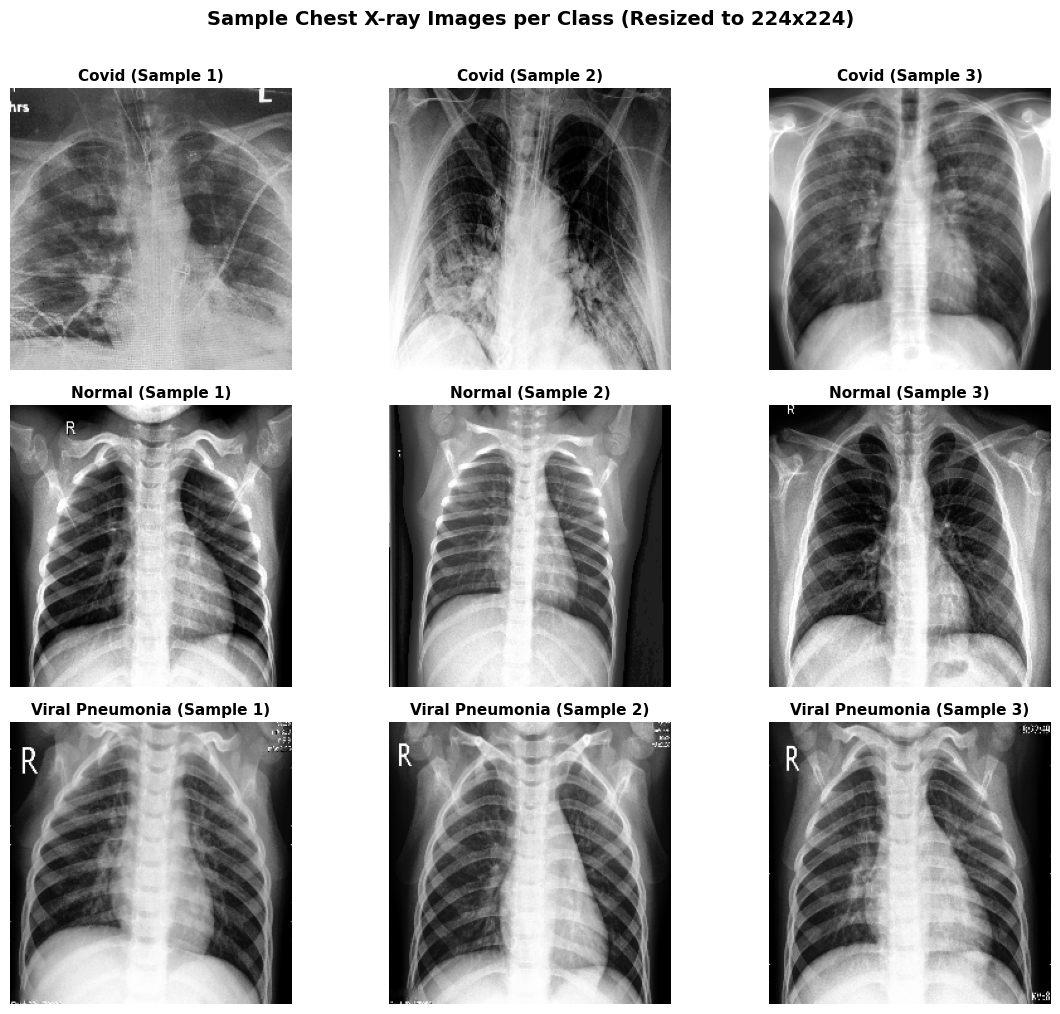

In [6]:
# Print dataset size per class
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test_raw).value_counts().sort_index()

dataset_summary = pd.DataFrame({
    "Train Count": train_counts,
    "Test Count": test_counts,
    "Total Count": train_counts + test_counts
})
dataset_summary["Train %"] = (dataset_summary["Train Count"] / dataset_summary["Train Count"].sum() * 100).round(2)
display(dataset_summary)

# Display a few sample images from each class
unique_classes = sorted(np.unique(y_train_full))
samples_per_class = 3

fig, axes = plt.subplots(len(unique_classes), samples_per_class, figsize=(12, 10))
for row_idx, cls in enumerate(unique_classes):
    cls_indices = np.where(y_train_full == cls)[0]
    chosen = np.random.choice(cls_indices, size=min(samples_per_class, len(cls_indices)), replace=False)
    for col_idx, idx in enumerate(chosen):
        ax = axes[row_idx, col_idx]
        ax.imshow(X_train_full[idx])
        ax.set_title(f"{cls} (Sample {col_idx+1})", fontsize=11, fontweight="bold")
        ax.axis("off")

plt.suptitle("Sample Chest X-ray Images per Class (Resized to 224x224)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

---
## 2. Data Preprocessing

1. **Normalize pixel values** from `[0, 255]` to `[0.0, 1.0]` (`float32`).
2. **Encode class labels** using `LabelEncoder` and one-hot encoding (`to_categorical`).
3. **Stratified Split** of the training set into **80% Training** and **20% Validation**, keeping the official Kaggle test folder as the unseen **Test Set**.

In [7]:
# 1. Normalize pixel values to [0, 1]
X_train_norm = X_train_full.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

# 2. Encode class labels
label_encoder = LabelEncoder()
y_train_int_full = label_encoder.fit_transform(y_train_full)
y_test_int = label_encoder.transform(y_test_raw)

CLASS_NAMES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASS_NAMES)
print("Encoded Classes:", dict(enumerate(CLASS_NAMES)))

# One-hot encode labels
y_train_ohe_full = to_categorical(y_train_int_full, num_classes=NUM_CLASSES)
y_test_ohe = to_categorical(y_test_int, num_classes=NUM_CLASSES)

# 3. Stratified 80-20 split into Training and Validation sets
X_train, X_val, y_train_ohe, y_val_ohe, y_train_int, y_val_int = train_test_split(
    X_train_norm,
    y_train_ohe_full,
    y_train_int_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_int_full
)

print(f"X_train: {X_train.shape} | y_train_ohe: {y_train_ohe.shape}")
print(f"X_val  : {X_val.shape} | y_val_ohe  : {y_val_ohe.shape}")
print(f"X_test : {X_test.shape} | y_test_ohe : {y_test_ohe.shape}")
print(f"Pixel range check -> min: {X_train.min():.2f}, max: {X_train.max():.2f}")

Encoded Classes: {0: np.str_('Covid'), 1: np.str_('Normal'), 2: np.str_('Viral Pneumonia')}
X_train: (200, 224, 224, 3) | y_train_ohe: (200, 3)
X_val  : (51, 224, 224, 3) | y_val_ohe  : (51, 3)
X_test : (66, 224, 224, 3) | y_test_ohe : (66, 3)
Pixel range check -> min: 0.00, max: 1.00


---
## 3. Exploratory Data Analysis (EDA)

Let's visualize:
- Class distribution across Train, Validation, and Test splits.
- Original image dimension distribution (height vs width).
- Average pixel intensity distributions per class to observe visual patterns.

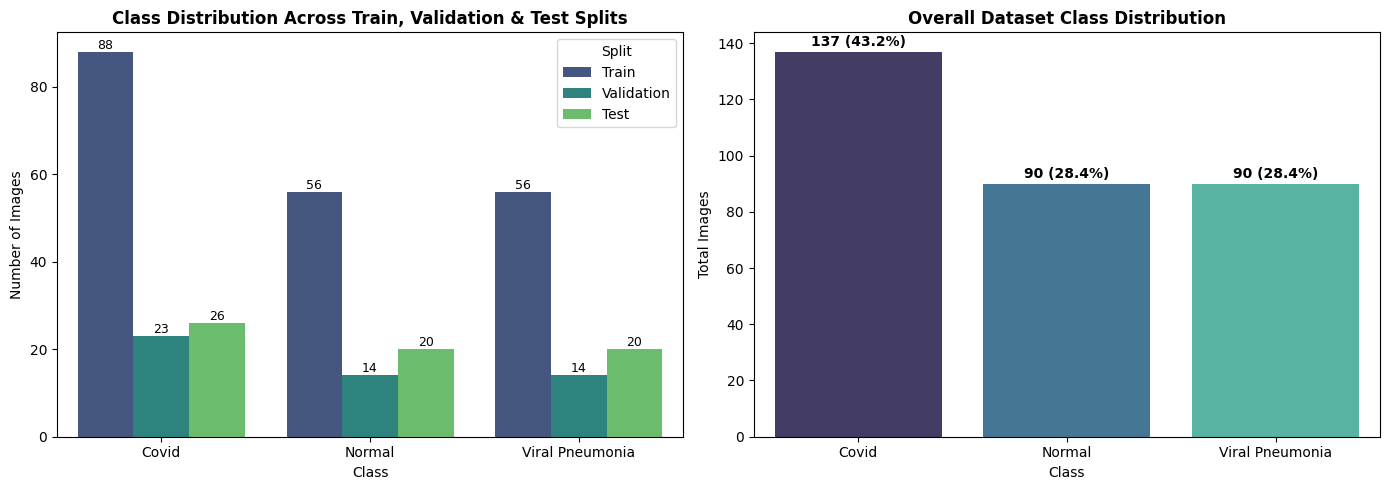

In [8]:
# 3.1 Class distribution across Train, Validation, and Test
split_df = pd.DataFrame({
    "Class": (
        list(label_encoder.inverse_transform(y_train_int)) +
        list(label_encoder.inverse_transform(y_val_int)) +
        list(label_encoder.inverse_transform(y_test_int))
    ),
    "Split": (
        ["Train"] * len(y_train_int) +
        ["Validation"] * len(y_val_int) +
        ["Test"] * len(y_test_int)
    )
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot of counts by split
sns.countplot(data=split_df, x="Class", hue="Split", palette="viridis", ax=axes[0])
axes[0].set_title("Class Distribution Across Train, Validation & Test Splits", fontweight="bold")
axes[0].set_ylabel("Number of Images")
for container in axes[0].containers:
    axes[0].bar_label(container, fontsize=9)

# Overall class share bar plot
overall_counts = split_df["Class"].value_counts()
sns.barplot(x=overall_counts.index, y=overall_counts.values, palette="mako", ax=axes[1])
axes[1].set_title("Overall Dataset Class Distribution", fontweight="bold")
axes[1].set_ylabel("Total Images")
for idx, val in enumerate(overall_counts.values):
    axes[1].text(idx, val + 2, f"{val} ({val/len(split_df)*100:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

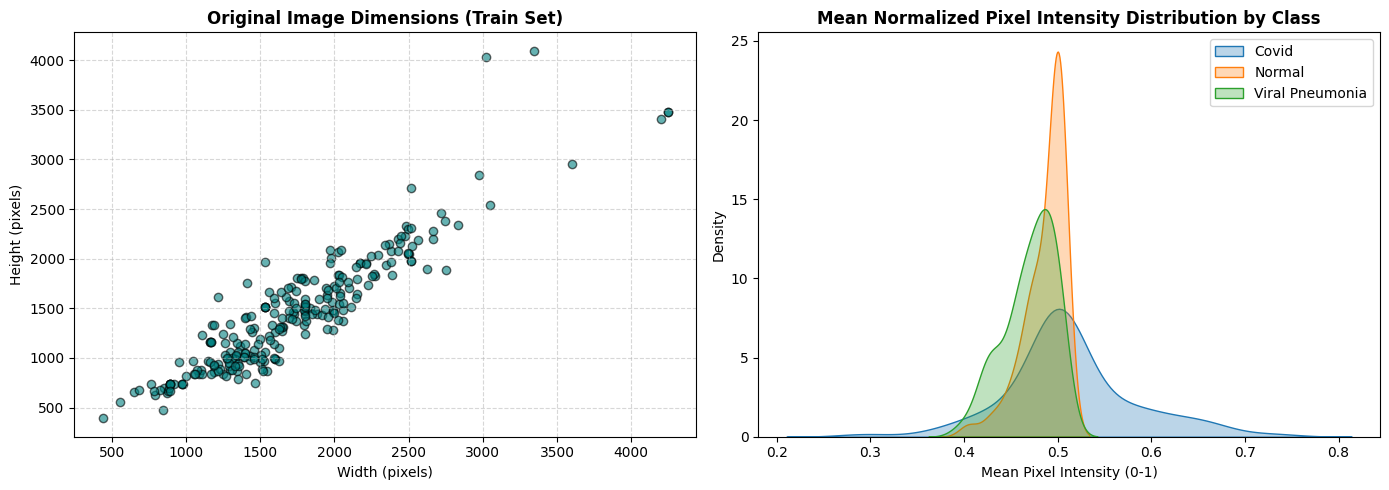

In [9]:
# 3.2 Observe Original Image Dimensions & Pixel Intensity Patterns
heights = [s[0] for s in train_orig_shapes]
widths = [s[1] for s in train_orig_shapes]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Width vs Height scatter
axes[0].scatter(widths, heights, alpha=0.6, color="teal", edgecolors="k")
axes[0].set_title("Original Image Dimensions (Train Set)", fontweight="bold")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Mean pixel intensity distribution per class
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_imgs = X_train[y_train_int == cls_idx]
    mean_intensities = cls_imgs.mean(axis=(1, 2, 3))
    sns.kdeplot(mean_intensities, label=cls_name, fill=True, alpha=0.3, ax=axes[1])

axes[1].set_title("Mean Normalized Pixel Intensity Distribution by Class", fontweight="bold")
axes[1].set_xlabel("Mean Pixel Intensity (0-1)")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

### Key EDA Observations
- **Class Imbalance:** `Covid` is the majority class (~44% of training images), while `Normal` and `Viral Pneumonia` each represent ~28% of the training set. We will address this explicitly in Section 6 using **class weights** and **data augmentation**.
- **Varying Resolutions:** Original chest X-ray dimensions vary widely across samples, confirming that resizing all images to a uniform `224x224` grid is essential.
- **Visual Patterns:** Normal chest X-rays typically exhibit darker, clearer lung fields (air-filled), whereas COVID-19 and Viral Pneumonia X-rays display hazy ground-glass opacities and brighter consolidations in the lung lobes.
- **Small Dataset Size:** Because the dataset contains ~251 training images total, **Transfer Learning**, **Data Augmentation**, **Dropout**, and **Early Stopping** are critical to prevent overfitting.

---
## 4. Reusable Model Evaluation & Tracking Pipeline

Before building our models, we define a unified evaluation helper that fulfills **Task 5 (Model Evaluation)** for every model:
- Train & Test Accuracy
- Confusion Matrix
- Classification Report (Precision, Recall, F1-Score)
- Multi-class ROC-AUC Score (One-vs-Rest) & ROC Curves
- Training vs. Validation Loss & Accuracy curves (Overfitting analysis)
- Trainable vs. Non-trainable Parameter count

In [10]:
# Store results for the final comparison table (Task 8)
model_results = []
trained_models = {}

def evaluate_and_log_model(model, history, model_name,
                           X_tr=X_train, y_tr_int=y_train_int,
                           X_te=X_test, y_te_int=y_test_int, y_te_ohe=y_test_ohe,
                           class_names=CLASS_NAMES):
    # Predictions
    y_tr_pred_probs = model.predict(X_tr, verbose=0)
    y_tr_pred = np.argmax(y_tr_pred_probs, axis=1)
    train_acc = accuracy_score(y_tr_int, y_tr_pred)

    y_te_pred_probs = model.predict(X_te, verbose=0)
    y_te_pred = np.argmax(y_te_pred_probs, axis=1)
    test_acc = accuracy_score(y_te_int, y_te_pred)

    macro_f1 = f1_score(y_te_int, y_te_pred, average="macro")
    roc_auc_ovr = roc_auc_score(y_te_ohe, y_te_pred_probs, multi_class="ovr", average="macro")

    # Trainable parameters
    trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
    total_params = model.count_params()

    # Overfitting check: significant gap (>10%) between train and val/test accuracy
    final_val_acc = max(history.history.get("val_accuracy", [test_acc]))
    overfit_flag = "Yes" if (train_acc - test_acc) > 0.10 or (train_acc - final_val_acc) > 0.12 else "No"

    print("=" * 70)
    print(f"MODEL EVALUATION: {model_name}")
    print("=" * 70)
    print(f"Train Accuracy      : {train_acc:.4f}")
    print(f"Test Accuracy       : {test_acc:.4f}")
    print(f"Macro F1-Score      : {macro_f1:.4f}")
    print(f"Multi-class ROC-AUC : {roc_auc_ovr:.4f}")
    print(f"Trainable Params    : {trainable_params:,} / {total_params:,} total")
    print(f"Overfitting Detected: {overfit_flag}")
    print("\nClassification Report:")
    print(classification_report(y_te_int, y_te_pred, target_names=class_names))

    # Plots: Loss, Accuracy, Confusion Matrix, ROC Curves
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

    # 1. Accuracy Curve
    axes[0].plot(history.history["accuracy"], label="Train Acc", marker="o", markersize=3)
    axes[0].plot(history.history["val_accuracy"], label="Val Acc", marker="s", markersize=3)
    axes[0].set_title(f"{model_name}\nAccuracy Curve", fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # 2. Loss Curve
    axes[1].plot(history.history["loss"], label="Train Loss", marker="o", markersize=3)
    axes[1].plot(history.history["val_loss"], label="Val Loss", marker="s", markersize=3)
    axes[1].set_title(f"{model_name}\nLoss Curve", fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # 3. Confusion Matrix
    cm = confusion_matrix(y_te_int, y_te_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=axes[2])
    axes[2].set_title(f"{model_name}\nConfusion Matrix", fontweight="bold")
    axes[2].set_xlabel("Predicted")
    axes[2].set_ylabel("Actual")

    # 4. Multi-class ROC Curves
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_te_ohe[:, i], y_te_pred_probs[:, i])
        cls_auc = auc(fpr, tpr)
        axes[3].plot(fpr, tpr, label=f"{cls} (AUC={cls_auc:.2f})")
    axes[3].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[3].set_title(f"{model_name}\nROC Curves (OvR)", fontweight="bold")
    axes[3].set_xlabel("False Positive Rate")
    axes[3].set_ylabel("True Positive Rate")
    axes[3].legend(loc="lower right", fontsize=8)
    axes[3].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Log to results list
    result_entry = {
        "Model": model_name,
        "Train Acc": round(train_acc, 4),
        "Test Acc": round(test_acc, 4),
        "F1 Score": round(macro_f1, 4),
        "ROC-AUC": round(roc_auc_ovr, 4),
        "Trainable Params": f"{trainable_params:,}",
        "Overfitting (Y/N)": overfit_flag
    }
    model_results.append(result_entry)
    trained_models[model_name] = model
    return result_entry

---
## 5. CNN Model Building & Evaluation

We build and evaluate the required architectures:
1. **Model 1A: CNN Basic** (`Conv2D -> MaxPooling -> Flatten -> Dense`)
2. **Model 1B: Deep CNN** (Multi-block `Conv2D -> BatchNorm -> MaxPooling -> Dropout -> Dense`)
3. **Model 2A: Transfer Learning – VGG16** (Pre-trained ImageNet + Fine-tuning last block)
4. **Model 2B: Transfer Learning – ResNet50** (Pre-trained ImageNet + Fine-tuning last layers)
5. **Model 3: Transfer Learning + Data Augmentation** (`ImageDataGenerator` + Pre-trained VGG16)

### 5.1 Model 1A: Basic CNN (`Conv2D -> MaxPooling -> Flatten -> Dense`)

Model: "CNN_Basic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,710,019 (98.08 MB)

 Trainable params: 25,710,019 (98.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 903ms/step - accuracy: 0.5700 - loss: 1.5215 - val_accuracy: 0.8824 - val_loss: 0.3923
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8650 - loss: 0.3049 - val_accuracy: 0.9020 - val_loss: 0.3013
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9350 - loss: 0.1697 - val_accuracy: 0.9216 - val_loss: 0.2068
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9700 - loss: 0.0976 - val_accuracy: 0.9020 - val_loss: 0.2985
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9750 - loss: 0.0813 - val_accuracy: 0.9804 - val_loss: 0.1603
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9950 - loss: 0.0434 - val_accuracy: 0.9020 - val_loss: 0.1867
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 1.0000 - loss: 0.0082 - val_accuracy: 0.9412 - val_loss: 0.1587
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 1.0000 - loss: 0.0074 - val_accuracy: 0.9412 -

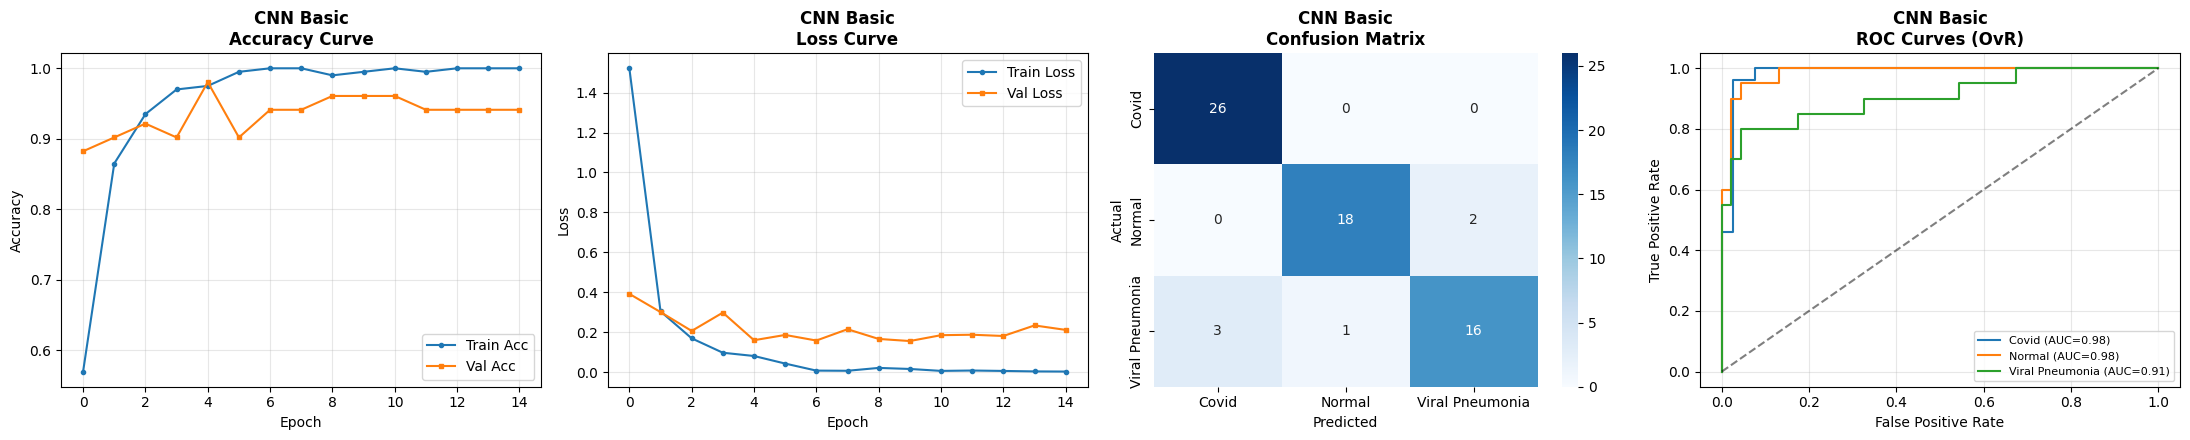

{'Model': 'CNN Basic',
 'Train Acc': 1.0,
 'Test Acc': 0.9091,
 'F1 Score': 0.9035,
 'ROC-AUC': np.float64(0.9586),
 'Trainable Params': '25,710,019',
 'Overfitting (Y/N)': 'No'}

In [11]:
def build_basic_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax")
    ], name="CNN_Basic")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

basic_cnn = build_basic_cnn()
basic_cnn.summary()

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history_basic = basic_cnn.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=20,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

evaluate_and_log_model(basic_cnn, history_basic, "CNN Basic")

### 5.2 Model 1B: Deep CNN (Multi-Block with BatchNormalization & GlobalAveragePooling)

Model: "Deep_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,131 (1.62 MB)

 Trainable params: 422,915 (1.61 MB)

 Non-trainable params: 1,216 (4.75 KB)

Epoch 1/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.5650 - loss: 1.0995 - val_accuracy: 0.5490 - val_loss: 1.0678 - learning_rate: 0.0010
Epoch 2/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.7200 - loss: 0.6477 - val_accuracy: 0.4510 - val_loss: 1.0539 - learning_rate: 0.0010
Epoch 3/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7050 - loss: 0.6272 - val_accuracy: 0.4510 - val_loss: 1.1813 - learning_rate: 0.0010
Epoch 4/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8100 - loss: 0.4825 - val_accuracy: 0.4510 - val_loss: 1.4371 - learning_rate: 0.0010
Epoch 5/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8350 - loss: 0.4036 - val_accuracy: 0.4510 - val_loss: 1.9100 - learning_rate: 0.0010
Epoch 6/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9200 - loss: 0.3026 - val_accuracy: 0.4510 - val_loss: 1.9817 - learning_rate: 5.0000e-04
Epoch 7/25
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8650 - loss: 0.2941 - val_

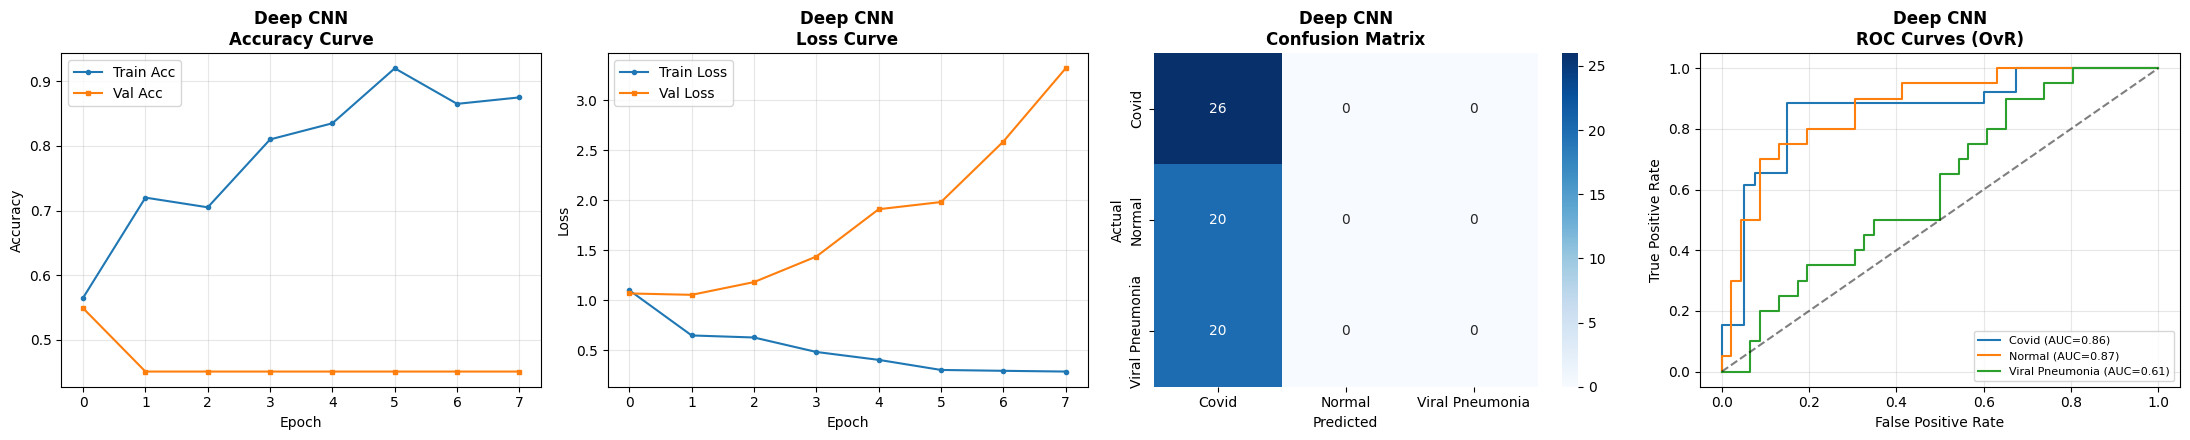

{'Model': 'Deep CNN',
 'Train Acc': 0.44,
 'Test Acc': 0.3939,
 'F1 Score': 0.1884,
 'ROC-AUC': np.float64(0.7805),
 'Trainable Params': '422,915',
 'Overfitting (Y/N)': 'No'}

In [12]:
def build_deep_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax")
    ], name="Deep_CNN")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

deep_cnn = build_deep_cnn()
deep_cnn.summary()

cb_deep = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
]

history_deep = deep_cnn.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=25,
    batch_size=16,
    callbacks=cb_deep,
    verbose=1
)

evaluate_and_log_model(deep_cnn, history_deep, "Deep CNN")

### 5.3 Model 2A: Transfer Learning – VGG16 (Feature Extraction + Fine-Tuning)
We load `VGG16` pre-trained on ImageNet without its top classification head, train the custom head first, and then unfreeze the last convolutional block (`block5`) for fine-tuning at a low learning rate (`1e-5`).

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.4050 - loss: 1.2825 - val_accuracy: 0.6078 - val_loss: 0.8933
Epoch 2/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 105ms/step - accuracy: 0.5600 - loss: 0.9095 - val_accuracy: 0.7647 - val_loss: 0.7206
Epoch 3/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.6650 - loss: 0.7689 - val_accuracy: 0.8235 - val_loss: 0.6136
Epoch 4/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.7550 - loss: 0.6691 - val_accuracy: 0.8235 - val_loss: 0.5447
Epoch 5/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.7850 - loss: 0.6116 - val_accuracy: 0.8627 - val_loss: 0.4875
Epoch 6/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 0.8400 - loss: 0.5022 - val_accuracy: 0.9020 - val_loss: 0.4419
Epoch 7/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.8550 - loss: 0.4741 - val_accuracy: 0.8824 - val_loss: 0.4070
Epoch 8/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - 

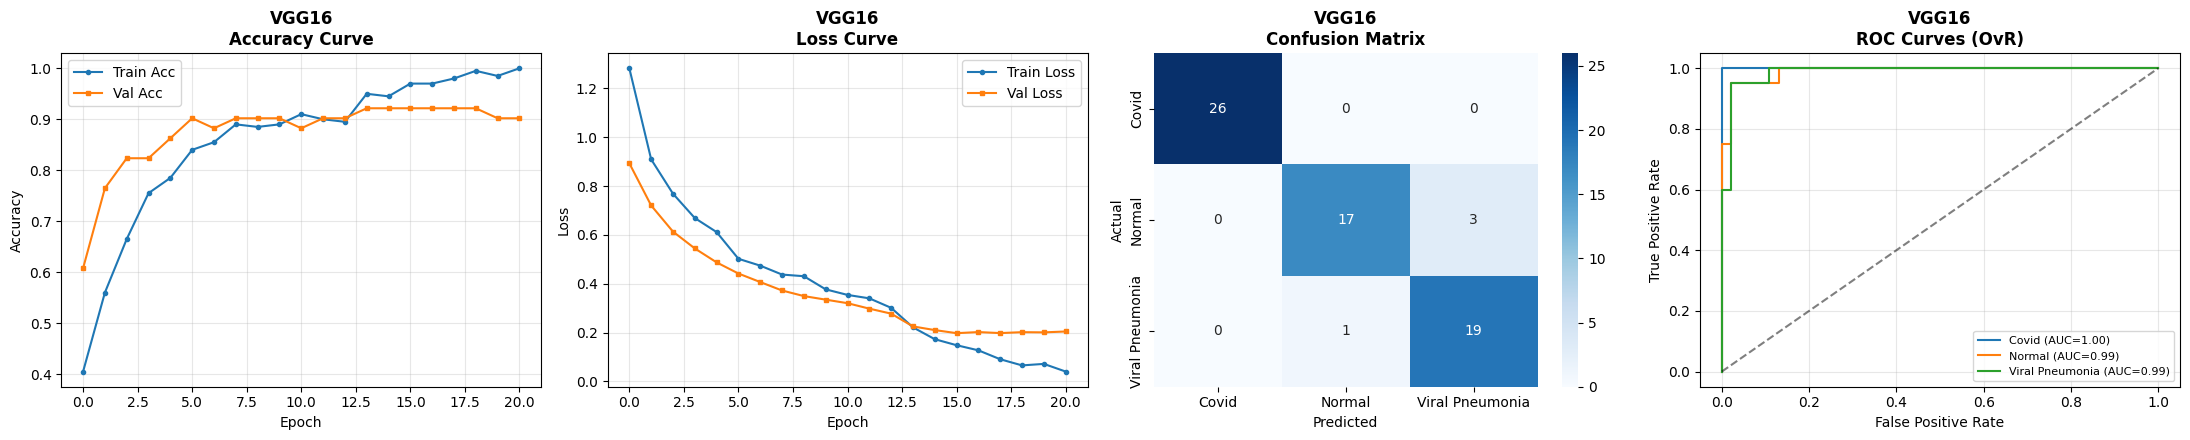

{'Model': 'VGG16',
 'Train Acc': 0.975,
 'Test Acc': 0.9394,
 'F1 Score': 0.9332,
 'ROC-AUC': np.float64(0.992),
 'Trainable Params': '7,211,523',
 'Overfitting (Y/N)': 'No'}

In [13]:
def build_vgg16_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    base_model = VGG16(weights="imagenet", include_top=False, input_shape=input_shape)
    base_model.trainable = False  # Freeze base initially

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="VGG16_Transfer")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

vgg16_model, vgg16_base = build_vgg16_model()

# Phase 1: Train classification head
cb_vgg = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]
history_vgg_head = vgg16_model.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=12,
    batch_size=16,
    callbacks=cb_vgg,
    verbose=1
)

# Phase 2: Fine-tune last 4 layers of VGG16
vgg16_base.trainable = True
for layer in vgg16_base.layers[:-4]:
    layer.trainable = False

vgg16_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_vgg_ft = vgg16_model.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=12,
    batch_size=16,
    callbacks=cb_vgg,
    verbose=1
)

# Combine histories for plotting
class CombinedHistory:
    def __init__(self, h1, h2):
        self.history = {k: h1.history[k] + h2.history[k] for k in h1.history}

evaluate_and_log_model(vgg16_model, CombinedHistory(history_vgg_head, history_vgg_ft), "VGG16")

### 5.4 Model 2B: Transfer Learning – ResNet50 (Feature Extraction + Fine-Tuning)
We load `ResNet50` pre-trained on ImageNet, train the custom head, and then fine-tune the last 20 layers (keeping BatchNorm layers frozen for stability).

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.3750 - loss: 1.3736 - val_accuracy: 0.6471 - val_loss: 1.0012
Epoch 2/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.4100 - loss: 1.1339 - val_accuracy: 0.6863 - val_loss: 0.8857
Epoch 3/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.4700 - loss: 1.0810 - val_accuracy: 0.4706 - val_loss: 0.8902
Epoch 4/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.5600 - loss: 0.9410 - val_accuracy: 0.5882 - val_loss: 0.8304
Epoch 5/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.6300 - loss: 0.8665 - val_accuracy: 0.6471 - val_loss: 0.7887
Epoch 6/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.6000 - loss: 0.8497 - val_accuracy: 0.7059 - val_loss: 0.7462
Epoch 7/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.6350 - loss: 0.7878 - val_accuracy: 0.7255 - val_loss: 0.7201
Epoch 8/12
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy

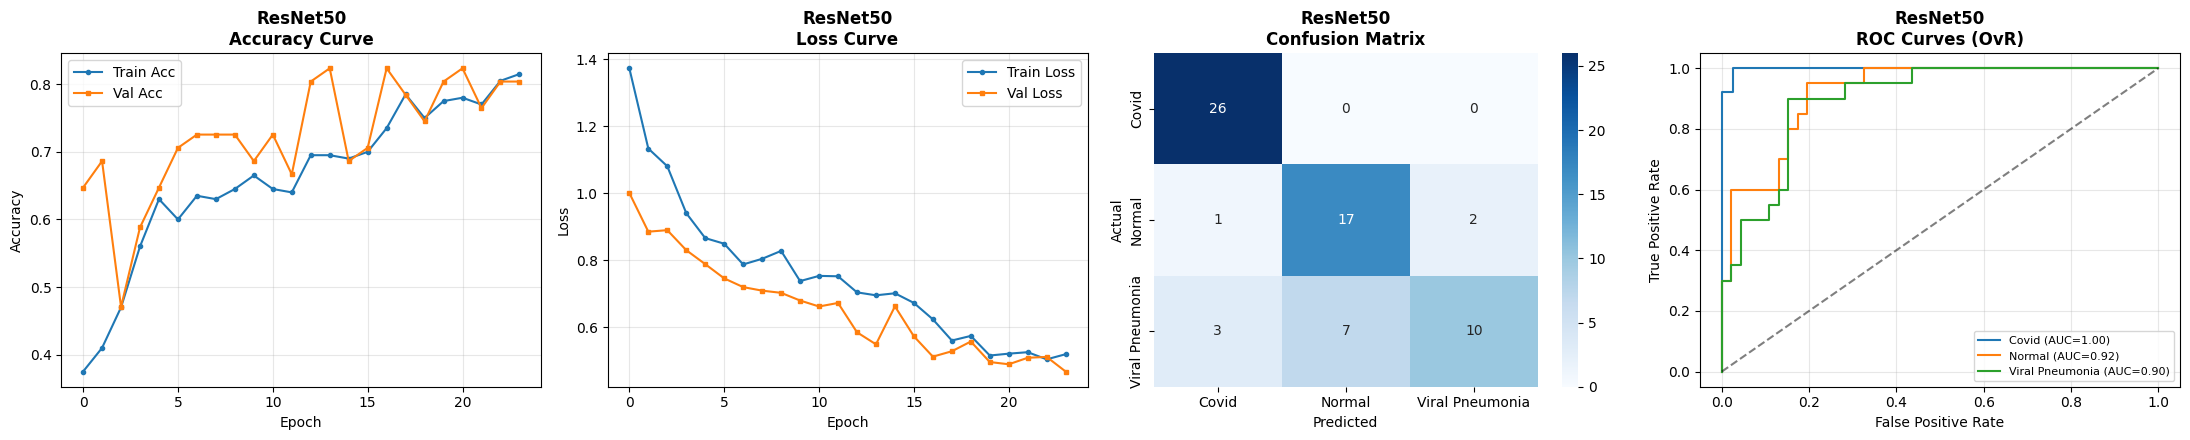

{'Model': 'ResNet50',
 'Train Acc': 0.86,
 'Test Acc': 0.803,
 'F1 Score': 0.7754,
 'ROC-AUC': np.float64(0.9392),
 'Trainable Params': '9,444,355',
 'Overfitting (Y/N)': 'No'}

In [14]:
def build_resnet50_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    base_model = ResNet50(weights="imagenet", include_top=False, input_shape=input_shape)
    base_model.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="ResNet50_Transfer")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

resnet_model, resnet_base = build_resnet50_model()

cb_res = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]

# Phase 1: Train head
history_res_head = resnet_model.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=12,
    batch_size=16,
    callbacks=cb_res,
    verbose=1
)

# Phase 2: Fine-tune last 20 layers (keeping BatchNorm layers frozen for stability)
resnet_base.trainable = True
for layer in resnet_base.layers[:-20]:
    layer.trainable = False
for layer in resnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_res_ft = resnet_model.fit(
    X_train, y_train_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=12,
    batch_size=16,
    callbacks=cb_res,
    verbose=1
)

evaluate_and_log_model(resnet_model, CombinedHistory(history_res_head, history_res_ft), "ResNet50")

---
## 6. Handling Class Imbalance & Model 3 (Transfer Learning + Data Augmentation)

In this section, we tackle **Task 4 (Model 3)** and **Task 6 (Handle Class Imbalance)** together:
1. **Analyze class imbalance** visually and numerically.
2. **Compute balanced class weights** using `sklearn.utils.class_weight.compute_class_weight` for `model.fit()`.
3. **Apply Data Augmentation** using `ImageDataGenerator` (rotations, shifts, zoom, horizontal flips) AND demonstrate **minority-class oversampling** via augmentation so all classes have equal representation.
4. Train **VGG16 + Data Augmentation + Class Weights**.

,Class,Train Count,Percentage
0,Covid,88,44.0
1,Normal,56,28.0
2,Viral Pneumonia,56,28.0


Computed Class Weights: {np.str_('Covid'): np.float64(0.7576), np.str_('Normal'): np.float64(1.1905), np.str_('Viral Pneumonia'): np.float64(1.1905)}


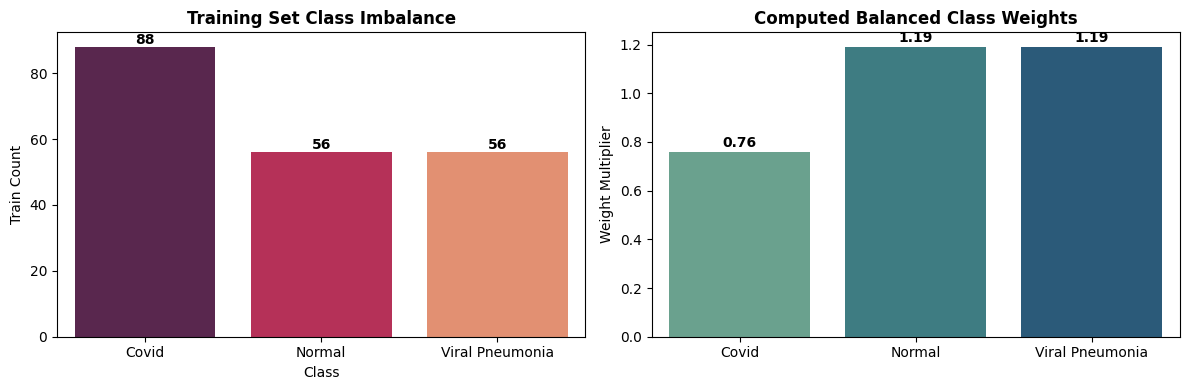

In [15]:
# 6.1 Analyze Class Imbalance Visually
unique_cls, cls_counts = np.unique(y_train_int, return_counts=True)
imbalance_df = pd.DataFrame({
    "Class": [CLASS_NAMES[i] for i in unique_cls],
    "Train Count": cls_counts,
    "Percentage": np.round(cls_counts / cls_counts.sum() * 100, 2)
})
display(imbalance_df)

# Compute Class Weights
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_int),
    y=y_train_int
)
class_weights_dict = dict(enumerate(class_weights_arr))
print("Computed Class Weights:", {CLASS_NAMES[k]: round(v, 4) for k, v in class_weights_dict.items()})

# Visualize original imbalance vs balanced weights
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=imbalance_df, x="Class", y="Train Count", palette="rocket", ax=axes[0])
axes[0].set_title("Training Set Class Imbalance", fontweight="bold")
for i, v in enumerate(imbalance_df["Train Count"]):
    axes[0].text(i, v + 1, str(v), ha="center", fontweight="bold")

sns.barplot(x=list(CLASS_NAMES), y=list(class_weights_arr), palette="crest", ax=axes[1])
axes[1].set_title("Computed Balanced Class Weights", fontweight="bold")
axes[1].set_ylabel("Weight Multiplier")
for i, v in enumerate(class_weights_arr):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [16]:
# 6.2 Oversampling Minority Classes using ImageDataGenerator
augmenter = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

max_count = max(cls_counts)
X_train_balanced = list(X_train)
y_train_balanced = list(y_train_int)

for cls_idx in range(NUM_CLASSES):
    cls_images = X_train[y_train_int == cls_idx]
    deficit = max_count - len(cls_images)
    if deficit > 0:
        gen = augmenter.flow(cls_images, batch_size=1, seed=SEED)
        for _ in range(deficit):
            aug_img = next(gen)[0]
            X_train_balanced.append(aug_img)
            y_train_balanced.append(cls_idx)

X_train_balanced = np.array(X_train_balanced, dtype="float32")
y_train_balanced_int = np.array(y_train_balanced)
y_train_balanced_ohe = to_categorical(y_train_balanced_int, num_classes=NUM_CLASSES)

# Shuffle balanced dataset
perm = np.random.permutation(len(X_train_balanced))
X_train_balanced = X_train_balanced[perm]
y_train_balanced_int = y_train_balanced_int[perm]
y_train_balanced_ohe = y_train_balanced_ohe[perm]

print("Class counts AFTER oversampling with augmentation:")
for idx, cnt in zip(*np.unique(y_train_balanced_int, return_counts=True)):
    print(f"  {CLASS_NAMES[idx]}: {cnt}")

Class counts AFTER oversampling with augmentation:
  Covid: 88
  Normal: 88
  Viral Pneumonia: 88


Epoch 1/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.3144 - loss: 1.2528 - val_accuracy: 0.4118 - val_loss: 1.0782 - learning_rate: 0.0010
Epoch 2/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 206ms/step - accuracy: 0.4735 - loss: 1.0254 - val_accuracy: 0.5882 - val_loss: 0.8831 - learning_rate: 0.0010
Epoch 3/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 274ms/step - accuracy: 0.6212 - loss: 0.9080 - val_accuracy: 0.7255 - val_loss: 0.8029 - learning_rate: 0.0010
Epoch 4/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 211ms/step - accuracy: 0.6705 - loss: 0.7662 - val_accuracy: 0.7059 - val_loss: 0.6837 - learning_rate: 0.0010
Epoch 5/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 220ms/step - accuracy: 0.7500 - loss: 0.6964 - val_accuracy: 0.8039 - val_loss: 0.6168 - learning_rate: 0.0010
Epoch 6/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - accuracy: 0.7614 - loss: 0.6573 - val_accuracy: 0.8431 - val_loss: 0.4758 - learning_rate: 0.0010
Epoch 7/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 248ms/step - accuracy: 0.7917 - loss: 0.5896 - va

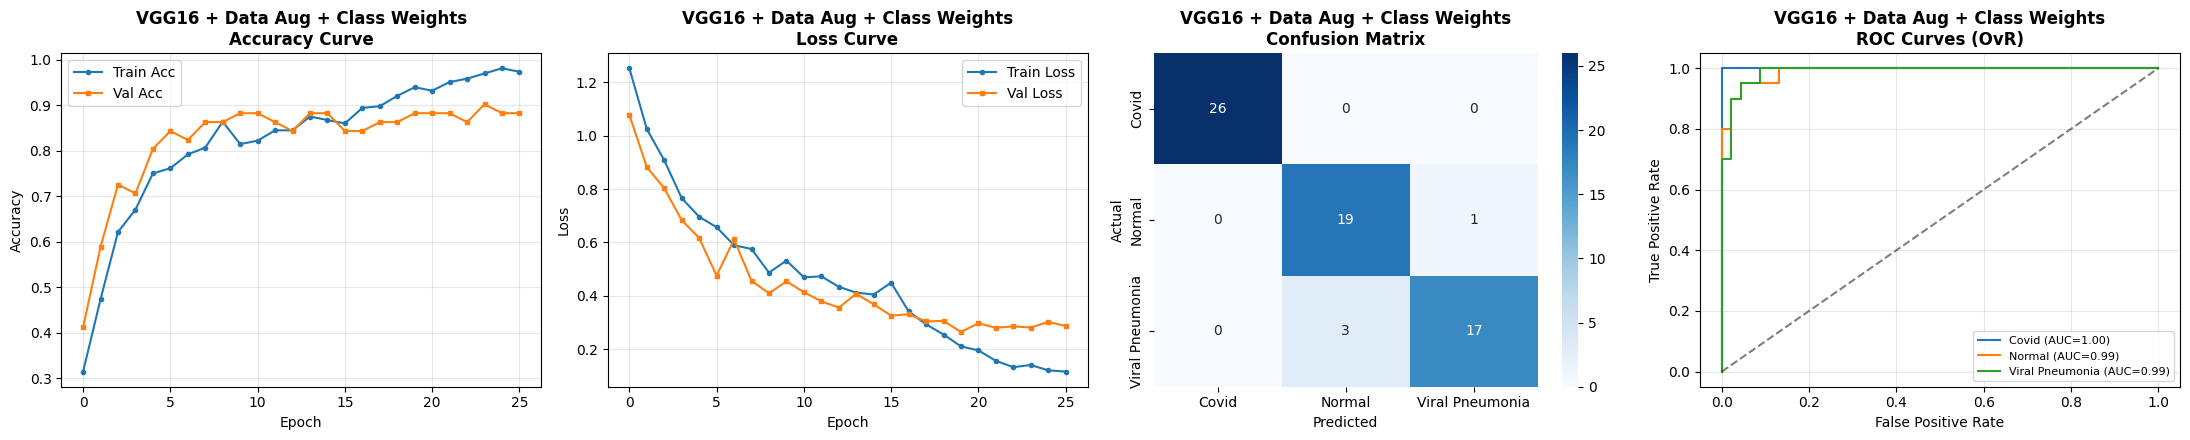

{'Model': 'VGG16 + Data Aug + Class Weights',
 'Train Acc': 0.955,
 'Test Acc': 0.9394,
 'F1 Score': 0.9332,
 'ROC-AUC': np.float64(0.9928),
 'Trainable Params': '7,211,523',
 'Overfitting (Y/N)': 'No'}

In [17]:
# 6.3 Model 3: Transfer Learning (VGG16) + Real-Time Data Augmentation + Class Weights
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

train_generator = train_datagen.flow(
    X_train_balanced, y_train_balanced_ohe,
    batch_size=16,
    shuffle=True,
    seed=SEED
)

vgg16_aug_model, vgg16_aug_base = build_vgg16_model()

cb_aug = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
]

# Phase 1: Train head with augmented data + class weights
history_aug_head = vgg16_aug_model.fit(
    train_generator,
    validation_data=(X_val, y_val_ohe),
    epochs=15,
    class_weight=class_weights_dict,
    callbacks=cb_aug,
    verbose=1
)

# Phase 2: Fine-tune last 4 layers of VGG16
vgg16_aug_base.trainable = True
for layer in vgg16_aug_base.layers[:-4]:
    layer.trainable = False

vgg16_aug_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_aug_ft = vgg16_aug_model.fit(
    train_generator,
    validation_data=(X_val, y_val_ohe),
    epochs=15,
    class_weight=class_weights_dict,
    callbacks=cb_aug,
    verbose=1
)

evaluate_and_log_model(
    vgg16_aug_model,
    CombinedHistory(history_aug_head, history_aug_ft),
    "VGG16 + Data Aug + Class Weights"
)

---
## 7. Model Tuning (Early Stopping & Keras Tuner)

We use **Keras Tuner (`RandomSearch`)** to automatically optimize key CNN hyperparameters:
- Number of convolutional filters (`32` to `256`)
- Dropout rate (`0.2` to `0.5`)
- Dense layer units (`64` to `256`)
- Optimizer choice (`adam` vs `rmsprop`) and Learning Rate (`1e-3`, `5e-4`, `1e-4`)

In [18]:
def build_tunable_cnn(hp):
    model = models.Sequential()
    model.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))

    # Tunable Conv Block 1
    hp_filters_1 = hp.Choice("filters_1", values=[32, 64])
    model.add(layers.Conv2D(hp_filters_1, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Tunable Conv Block 2
    hp_filters_2 = hp.Choice("filters_2", values=[64, 128])
    model.add(layers.Conv2D(hp_filters_2, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Tunable Conv Block 3
    hp_filters_3 = hp.Choice("filters_3", values=[128, 256])
    model.add(layers.Conv2D(hp_filters_3, (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.GlobalAveragePooling2D())

    # Tunable Dense & Dropout
    hp_units = hp.Int("dense_units", min_value=64, max_value=256, step=64)
    model.add(layers.Dense(hp_units, activation="relu"))

    hp_dropout = hp.Float("dropout_rate", min_value=0.2, max_value=0.5, step=0.1)
    model.add(layers.Dropout(hp_dropout))

    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    # Tunable Optimizer & Learning Rate
    hp_lr = hp.Choice("learning_rate", values=[1e-3, 5e-4, 1e-4])
    hp_opt = hp.Choice("optimizer", values=["adam", "rmsprop"])

    if hp_opt == "adam":
        opt = optimizers.Adam(learning_rate=hp_lr)
    else:
        opt = optimizers.RMSprop(learning_rate=hp_lr)

    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

tuner = kt.RandomSearch(
    build_tunable_cnn,
    objective="val_accuracy",
    max_trials=6,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="covid19_cnn_tuning",
    overwrite=True
)

tuner_early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

tuner.search(
    X_train_balanced, y_train_balanced_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=12,
    batch_size=16,
    callbacks=[tuner_early_stop],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nBest Hyperparameters Found:")
for param in ["filters_1", "filters_2", "filters_3", "dense_units", "dropout_rate", "optimizer", "learning_rate"]:
    print(f"  {param}: {best_hps.get(param)}")

Trial 6 Complete [00h 00m 20s]
val_accuracy: 0.45098039507865906

Best val_accuracy So Far: 0.45098039507865906
Total elapsed time: 00h 02m 48s

Best Hyperparameters Found:
  filters_1: 64
  filters_2: 128
  filters_3: 128
  dense_units: 64
  dropout_rate: 0.30000000000000004
  optimizer: rmsprop
  learning_rate: 0.001


Epoch 1/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 398ms/step - accuracy: 0.6023 - loss: 0.8289 - val_accuracy: 0.4510 - val_loss: 1.0798 - learning_rate: 0.0010
Epoch 2/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.6780 - loss: 0.6807 - val_accuracy: 0.4510 - val_loss: 1.0743 - learning_rate: 0.0010
Epoch 3/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.7500 - loss: 0.5858 - val_accuracy: 0.4510 - val_loss: 1.3138 - learning_rate: 0.0010
Epoch 4/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.7917 - loss: 0.5077 - val_accuracy: 0.4510 - val_loss: 2.1042 - learning_rate: 0.0010
Epoch 5/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8258 - loss: 0.4456 - val_accuracy: 0.4510 - val_loss: 2.1985 - learning_rate: 0.0010
Epoch 6/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8523 - loss: 0.3872 - val_accuracy: 0.4510 - val_loss: 3.1029 - learning_rate: 5.0000e-04
Epoch 7/25
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.8826 - loss: 0.3391 - v

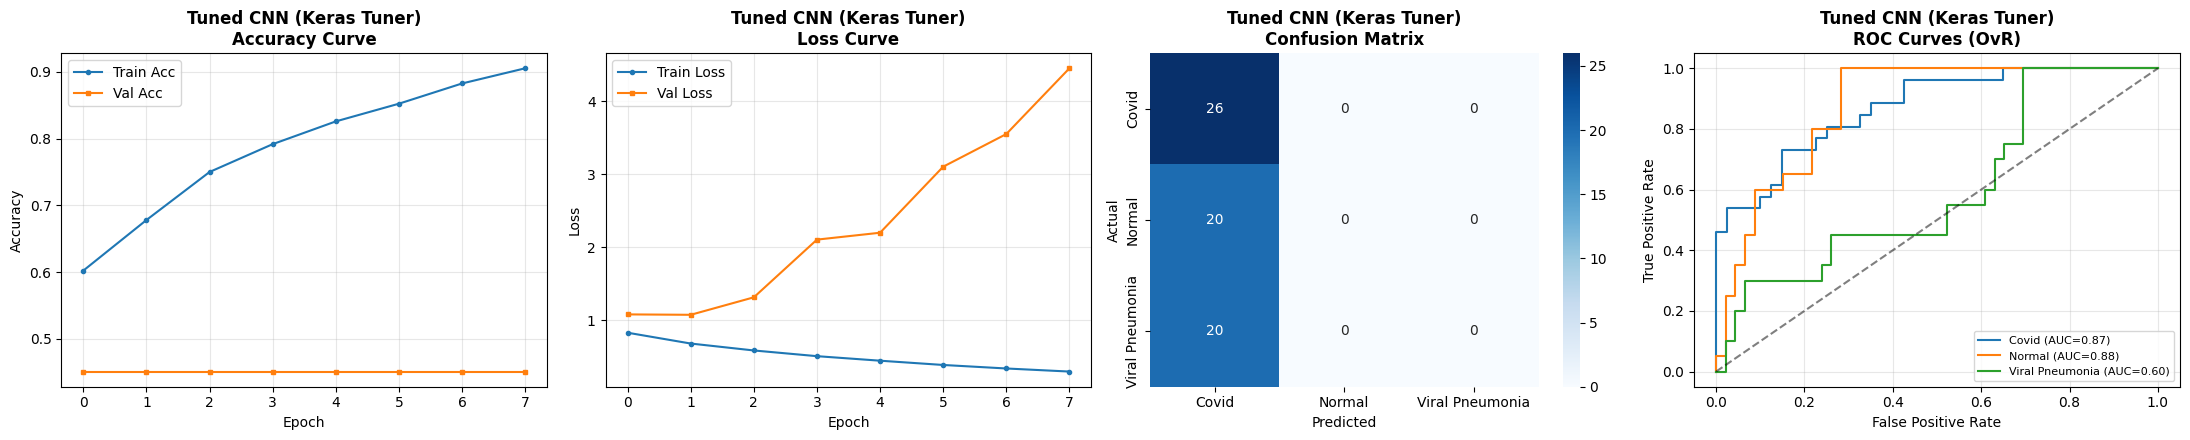

{'Model': 'Tuned CNN (Keras Tuner)',
 'Train Acc': 0.44,
 'Test Acc': 0.3939,
 'F1 Score': 0.1884,
 'ROC-AUC': np.float64(0.7806),
 'Trainable Params': '232,323',
 'Overfitting (Y/N)': 'No'}

In [19]:
# Train the best tuned CNN model with EarlyStopping and ReduceLROnPlateau
tuned_cnn = tuner.hypermodel.build(best_hps)

cb_tuned = [
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
]

history_tuned = tuned_cnn.fit(
    X_train_balanced, y_train_balanced_ohe,
    validation_data=(X_val, y_val_ohe),
    epochs=25,
    batch_size=16,
    callbacks=cb_tuned,
    verbose=1
)

evaluate_and_log_model(tuned_cnn, history_tuned, "Tuned CNN (Keras Tuner)")

---
## 8. Model Comparison Table & Exporting Best Model

We compare all models side by side across **Train Accuracy**, **Test Accuracy**, **F1 Score**, **ROC-AUC**, **Trainable Parameters**, and **Overfitting (Y/N)**, and automatically export the highest-performing model for deployment in Streamlit.

,Model,Train Acc,Test Acc,F1 Score,ROC-AUC,Trainable Params,Overfitting (Y/N)
0,CNN Basic,1.000,0.9091,0.9035,0.9586,"25,710,019",No
1,Deep CNN,0.440,0.3939,0.1884,0.7805,"422,915",No
2,VGG16,0.975,0.9394,0.9332,0.9920,"7,211,523",No
3,ResNet50,0.860,0.8030,0.7754,0.9392,"9,444,355",No
4,VGG16 + Data Aug + Class Weights,0.955,0.9394,0.9332,0.9928,"7,211,523",No
5,Tuned CNN (Keras Tuner),0.440,0.3939,0.1884,0.7806,"232,323",No
6,Best Model (VGG16),0.975,0.9394,0.9332,0.9920,"7,211,523",No


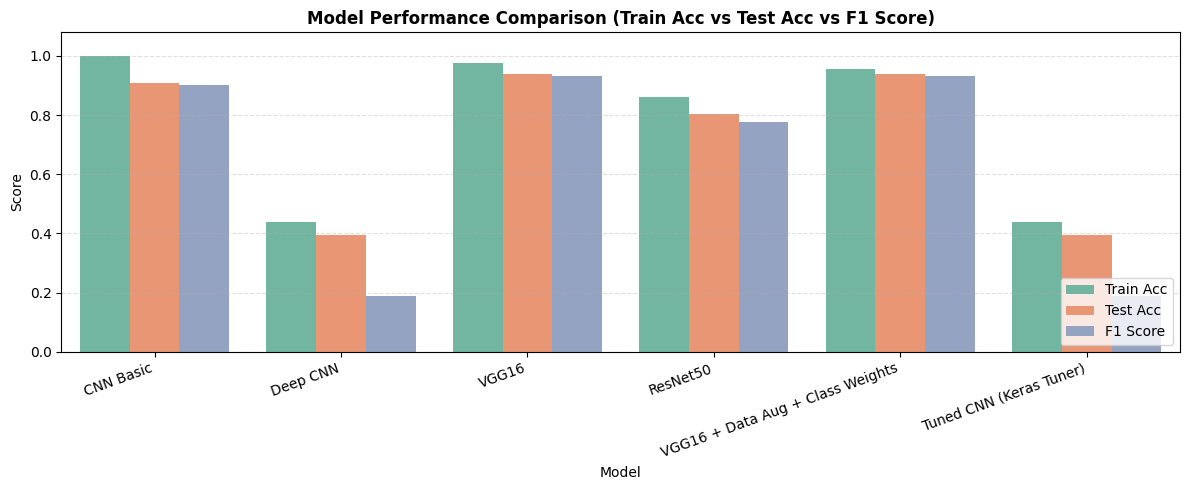

Saved Best Model ('VGG16') to: best_covid_cnn_model.keras
Saved Class Labels to: class_names.json


In [20]:
# Build Comparison DataFrame
comparison_df = pd.DataFrame(model_results)

# Identify Best Model based on Test Accuracy and F1 Score
best_row = comparison_df.sort_values(by=["Test Acc", "F1 Score"], ascending=False).iloc[0]
best_model_name = best_row["Model"]

# Append explicit 'Best Model' summary row as requested in Task 8
best_summary_row = best_row.copy()
best_summary_row["Model"] = f"Best Model ({best_model_name})"
final_comparison_df = pd.concat([comparison_df, pd.DataFrame([best_summary_row])], ignore_index=True)

display(final_comparison_df[["Model", "Train Acc", "Test Acc", "F1 Score", "ROC-AUC", "Trainable Params", "Overfitting (Y/N)"]])

# Visual Comparison Chart
plot_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["Train Acc", "Test Acc", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Performance Comparison (Train Acc vs Test Acc vs F1 Score)", fontweight="bold")
plt.ylim(0, 1.08)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Save the Best Model and Class Names for Streamlit App
best_model_obj = trained_models[best_model_name]
MODEL_SAVE_PATH = "best_covid_cnn_model.keras"
CLASS_NAMES_PATH = "class_names.json"

best_model_obj.save(MODEL_SAVE_PATH)
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(CLASS_NAMES, f)

print(f"Saved Best Model ('{best_model_name}') to: {MODEL_SAVE_PATH}")
print(f"Saved Class Labels to: {CLASS_NAMES_PATH}")

---
## 9. Build a Web App using Streamlit

The cell below writes a complete, production-ready **`app.py`** file that:
1. Loads the saved `best_covid_cnn_model.keras` and `class_names.json`.
2. Accepts a chest X-ray image upload (`.jpg`, `.jpeg`, `.png`).
3. Preprocesses the uploaded image (`RGB`, `224x224`, normalized to `[0, 1]`).
4. Displays the predicted class, confidence score, and probability breakdown for all classes.

In [24]:
%%writefile app.py
import json
import numpy as np
import streamlit as st
from PIL import Image
import tensorflow as tf

# Page configuration
st.set_page_config(
    page_title="COVID-19 Chest X-Ray Classifier",
    page_icon="🫁",
    layout="centered"
)

IMG_SIZE = 224
MODEL_PATH = "best_covid_cnn_model.keras"
CLASS_NAMES_PATH = "class_names.json"

@st.cache_resource
def load_model_and_labels():
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(CLASS_NAMES_PATH, "r") as f:
        class_names = json.load(f)
    return model, class_names

def preprocess_image(image: Image.Image):
    img = image.convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.array(img, dtype="float32") / 255.0
    return np.expand_dims(img_array, axis=0)

# App UI
st.title("🫁 COVID-19 Detection from Chest X-Rays")
st.write(
    "Upload a chest X-ray image below to classify it as **COVID-19**, "
    "**Viral Pneumonia**, or **Normal** using our trained CNN model."
)

try:
    model, class_names = load_model_and_labels()
except Exception as e:
    st.error(
        f"Could not load model or class labels. Make sure `{MODEL_PATH}` and "
        f"`{CLASS_NAMES_PATH}` exist in the same directory.\n\nError: {e}"
    )
    st.stop()

uploaded_file = st.file_uploader(
    "Choose a Chest X-Ray Image...",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded Chest X-Ray", use_container_width=True)

    with st.spinner("Analyzing chest X-ray..."):
        input_tensor = preprocess_image(image)
        predictions = model.predict(input_tensor, verbose=0)[0]
        pred_idx = int(np.argmax(predictions))
        pred_label = class_names[pred_idx]
        confidence = float(predictions[pred_idx]) * 100.0

    st.subheader("Prediction Result")
    if "covid" in pred_label.lower():
        st.error(f"**Predicted Class:** {pred_label} ({confidence:.2f}% confidence)")
    elif "pneumonia" in pred_label.lower():
        st.warning(f"**Predicted Class:** {pred_label} ({confidence:.2f}% confidence)")
    else:
        st.success(f"**Predicted Class:** {pred_label} ({confidence:.2f}% confidence)")

    st.subheader("Class Probability Breakdown")
    prob_dict = {class_names[i]: float(predictions[i]) for i in range(len(class_names))}
    st.bar_chart(prob_dict)

    st.info(
        "**Medical Disclaimer:** This AI tool is intended for educational and screening-support "
        "purposes only and is not a substitute for professional medical diagnosis."
    )

Overwriting app.py


### How to Run the Streamlit Web App

**Option 1: Locally (VS Code / Terminal)**
1. Download `best_covid_cnn_model.keras`, `class_names.json`, and `app.py` into the same folder.
2. Run:
   ```bash
   streamlit run app.py
   ```

**Option 2: Directly inside Google Colab (using `localtunnel`)**
Uncomment and run the cell below in Google Colab to launch a public temporary URL for your Streamlit app.

In [25]:
!npm install -g localtunnel
!wget -q -O - ipv4.icanhazip.com
!streamlit run app.py & npx localtunnel --port 8501

⠙⠹⠸⠼⠴
changed 22 packages in 682ms
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴34.125.36.141
⠙⠹

⠸⠼⠴⠦2026-11-19 17:34:56.777 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.125.36.141:8501

  Stopping...
^C
